# 02 · Baseline (TF-IDF + Logistic Regression) and the **Trustworthy** check

Experiment 1 (baseline) + a first run of Experiment 3 (trustworthiness) from our plan.

* Any heavier model (mBERT, XLM-R, MuRIL, HingBERT) must clearly beat this baseline.
* **Trustworthy = calibrated confidence**: when the model says 90 % sure, it should be right ~90 % of the time.
  * Measured with **ECE** (gap between *how sure* and *how right*) and a **reliability diagram**.
  * Fixed with **temperature scaling**: one number `T` fitted on validation; logits / T. F1 does not change, only the confidence.

The same `hinglish.calibration` code will be reused for the transformer models.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RAW_DIR = ROOT / "data/raw/Semeval_2020_task9_data/Hinglish"
PROC_DIR = ROOT / "data/processed"
FIG_DIR = ROOT / "results/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"negative": "#C0504D", "neutral": "#8A8FA3", "positive": "#377D72"}
from hinglish.data import load_splits, LABELS
from hinglish.calibration import ece_score, fit_temperature, apply_temperature, nll, plot_reliability
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from scipy.special import softmax

S = load_splits(PROC_DIR)
Xtr, ytr = S["train"].text, S["train"].label_id.values
Xva, yva = S["val"].text, S["val"].label_id.values
Xte, yte = S["test"].text, S["test"].label_id.values
print({k: len(v) for k, v in S.items()})

{'train': 14000, 'val': 3000, 'test': 3000}


## 1. Features

* **word n-grams (1-2)**: classic bag of words.
* **character n-grams (2-5)**: `bahut`, `bohot`, `bhot` share pieces like `bh`, `ho`, so char n-grams give some free robustness to spelling.

In [2]:
def build(C=1.0):
    feats = make_union(
        TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, lowercase=True, max_features=200_000),
    )
    return make_pipeline(feats, LogisticRegression(C=C, max_iter=3000))

# choose C on the validation set only (test stays untouched)
search = []
for C in [0.1, 0.25, 0.5, 1, 2, 4]:
    m = build(C).fit(Xtr, ytr)
    search.append({"C": C, "val_weighted_f1": f1_score(yva, m.predict(Xva), average="weighted")})
search = pd.DataFrame(search); display(search.round(4))
best_C = float(search.loc[search.val_weighted_f1.idxmax(), "C"]); print("best C =", best_C)

,C,val_weighted_f1
0,0.10,0.6148
1,0.25,0.6187
2,0.50,0.6235
3,1.00,0.6140
4,2.00,0.6087
5,4.00,0.5978


best C = 0.5


## 2. Accuracy on the held-out test set

In [3]:
model = build(best_C).fit(Xtr, ytr)
pred_te = model.predict(Xte)
res = {
    "model": "TF-IDF (word+char) + LR",
    "test_weighted_f1": f1_score(yte, pred_te, average="weighted"),
    "test_macro_f1": f1_score(yte, pred_te, average="macro"),
    "test_accuracy": accuracy_score(yte, pred_te),
}
print(pd.Series(res).to_string())
print()
print(classification_report(yte, pred_te, target_names=LABELS, digits=3))
print("Reference (slide 10): SemEval-2020 mBERT baseline 65.4 F1 · winner (XLM-R + adversarial) 75.0 F1")

model               TF-IDF (word+char) + LR
test_weighted_f1                   0.687225
test_macro_f1                      0.690324
test_accuracy                      0.685333

              precision    recall  f1-score   support

    negative      0.735     0.692     0.713       900
     neutral      0.592     0.650     0.620      1100
    positive      0.760     0.718     0.738      1000

    accuracy                          0.685      3000
   macro avg      0.696     0.687     0.690      3000
weighted avg      0.691     0.685     0.687      3000

Reference (slide 10): SemEval-2020 mBERT baseline 65.4 F1 · winner (XLM-R + adversarial) 75.0 F1


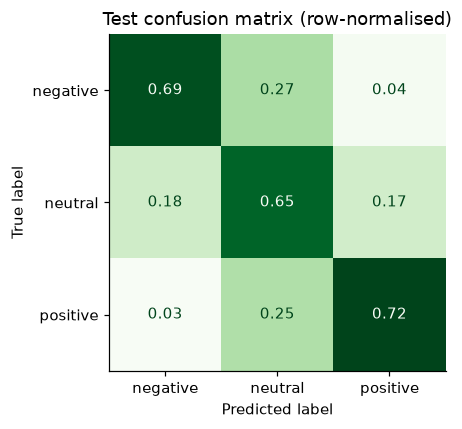

In [4]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(yte, pred_te, display_labels=LABELS, normalize="true", values_format=".2f", cmap="Greens", ax=ax, colorbar=False)
ax.set_title("Test confusion matrix (row-normalised)")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_baseline_confusion.png"); plt.show()

## 3. Trustworthy: is the confidence honest?

For logistic regression `decision_function` gives the **logits**; softmax of them = predicted probabilities. We fit `T` on **validation** logits, then judge on **test**.

In [5]:
logit_va = model.decision_function(Xva)
logit_te = model.decision_function(Xte)

T = fit_temperature(logit_va, yva)
p_before = softmax(logit_te, axis=1)
p_after = apply_temperature(logit_te, T)

calib = pd.DataFrame({
    "ECE (lower = more honest)": [ece_score(p_before, yte), ece_score(p_after, yte)],
    "NLL": [nll(logit_te, yte, 1.0), nll(logit_te, yte, T)],
    "mean confidence": [p_before.max(1).mean(), p_after.max(1).mean()],
    "accuracy": [(p_before.argmax(1) == yte).mean(), (p_after.argmax(1) == yte).mean()],
}, index=["before (T = 1)", f"after (T = {T:.2f})"])
display(calib.round(4))
print("T > 1 means the model was over-confident; T < 1 means under-confident. Accuracy is identical by design.")

,ECE (lower = more honest),NLL,mean confidence,accuracy
before (T = 1),0.0732,0.7287,0.6122,0.6853
after (T = 0.93),0.0605,0.7215,0.6265,0.6853


T > 1 means the model was over-confident; T < 1 means under-confident. Accuracy is identical by design.


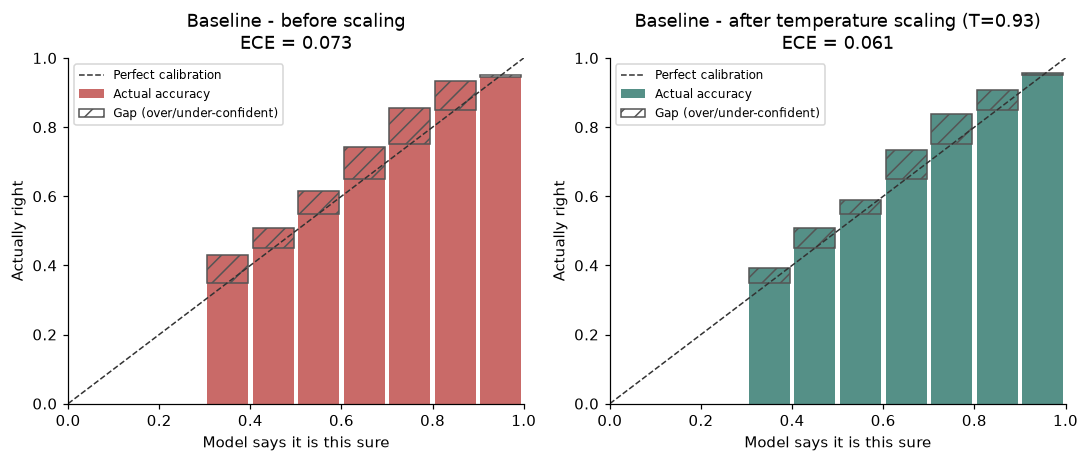

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
plot_reliability(axes[0], p_before, yte, "Baseline - before scaling", color="#C0504D")
plot_reliability(axes[1], p_after, yte, f"Baseline - after temperature scaling (T={T:.2f})", color="#377D72")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_baseline_reliability.png"); plt.show()

### What does "90 % sure" actually mean for this model?

In [7]:
conf = p_before.max(1); correct = p_before.argmax(1) == yte
for lo in [0.5, 0.7, 0.8, 0.9]:
    m = conf >= lo
    if m.any():
        print(f"says >= {lo:.0%} sure: {m.sum():5d} tweets, actually right {correct[m].mean():.1%}")

says >= 50% sure:  2217 tweets, actually right 75.0%
says >= 70% sure:   793 tweets, actually right 89.5%
says >= 80% sure:   392 tweets, actually right 93.6%
says >= 90% sure:   107 tweets, actually right 94.4%


## 4. Try one tweet (the example from our slides)

In [8]:
def predict(text, T=T):
    from hinglish.data import normalise
    z = model.decision_function([normalise(text)])
    p = apply_temperature(z, T)[0]
    return {"label": LABELS[p.argmax()], "scores": {l[:3]: round(float(s), 2) for l, s in zip(LABELS, p)}}

for t in ["Movie ekdum bakwas thi, total waste of time",
          "All the best Team India jeet ke aana",
          "Nahi wo is news ko defend kerne ki koshesh ker rhe hain h"]:
    print(f"{t!r:65} -> {predict(t)}")

'Movie ekdum bakwas thi, total waste of time'                     -> {'label': 'neutral', 'scores': {'neg': 0.15, 'neu': 0.52, 'pos': 0.33}}
'All the best Team India jeet ke aana'                            -> {'label': 'positive', 'scores': {'neg': 0.03, 'neu': 0.08, 'pos': 0.89}}
'Nahi wo is news ko defend kerne ki koshesh ker rhe hain h'       -> {'label': 'neutral', 'scores': {'neg': 0.38, 'neu': 0.55, 'pos': 0.07}}


## 5. Save results (for the final comparison table)

In [9]:
out = ROOT / "results"; out.mkdir(exist_ok=True)
res.update({"best_C": best_C, "temperature": T,
            "test_ece_before": float(calib.iloc[0, 0]), "test_ece_after": float(calib.iloc[1, 0])})
(out / "02_baseline_tfidf.json").write_text(json.dumps(res, indent=2))
print(json.dumps(res, indent=2))

{
  "model": "TF-IDF (word+char) + LR",
  "test_weighted_f1": 0.6872248024596962,
  "test_macro_f1": 0.6903235365548803,
  "test_accuracy": 0.6853333333333333,
  "best_C": 0.5,
  "temperature": 0.9322411782033655,
  "test_ece_before": 0.07315390772710458,
  "test_ece_after": 0.06051976122076449
}


## Takeaways

* This is the **number to beat** for every transformer model (Experiment 1).
* The calibration pipeline (ECE, reliability diagram, temperature scaling) is working end-to-end and will be applied unchanged to mBERT / XLM-R / MuRIL / HingBERT, where over-confidence is usually much stronger.
* Next: `03_transformers.ipynb` — fine-tune the four encoders with identical settings, 2–3 seeds (needs a GPU, e.g. Colab).